<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# How much of a season’s points difference comes from close games?

Start with all completed 2026 Six Nations matches, expand each result into home and away team rows, and reconcile their points with the separately fetched standings. Then split each team’s points difference between close games and wider margins. The real Rugby worker parses both sources; all reconciliation and classification happen in SQL.

The default replays **two actual public ESPN responses recorded on 14 November 2026**, not synthetic fixtures. They contain the full 15-match season and six-team table. A separate live mode requests the same settled season directly. These are ESPN records, not an independent verification or an official competition ruling. [Setup, exact URLs and capture checksums](README.md).

## Set a descriptive margin threshold

`CLOSE_MARGIN` is an integer **0–30 match points**, inclusive. A match is classified as close when the absolute final score difference is at most that value. Default **7**; experiment **14**. This is an analytical label, **not a claim about bonus-point eligibility or competition rules**.

`DATA_MODE` is **replay** or **live**. The season and source IDs stay fixed. Live mode clears inherited base-URL overrides and creates no replay server. Restart and run all after changes. The two source responses are independent reads, not an atomic snapshot; capture times identify retrieval, not match kickoff.

In [1]:
DATA_MODE = "replay"  # "live" requests the same 2026 season directly.
CLOSE_MARGIN = 7  # Inclusive absolute score margin in match points; experiment: 14.

In [2]:
import haybarn
import matplotlib.pyplot as plt
from IPython.display import display

from notebook_support import audit, chart, cleanup, configure, prose, theme

server, thread, previous, run_utc, provenance = configure(DATA_MODE, CLOSE_MARGIN)
source_label = (
    "Recorded ESPN responses • 2026-11-14 UTC"
    if DATA_MODE == "replay"
    else f"Live ESPN • retrieved {run_utc[:19]} UTC"
)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-rugby/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-rugby/notebooks/pyproject.toml.

## Connect to the tagged public worker

The literal command uses release v0.2.0 with pinned SDK, HTTP and Arrow packages. Replay serves the exact recorded JSON bytes through the worker’s supported base-URL hooks; the same worker parses the response in both modes. Its first launch needs internet for Git/packages and the extension, even when data mode is replay. No parent checkout or local worker environment is used.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'rugby' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-rugby@v0.2.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==25.0.1 --with httpx==0.28.1 vgi-rugby');
CREATE TABLE settings AS SELECT {{ CLOSE_MARGIN }}::INTEGER AS close_margin;

Running query in 'DuckDBPyConnection'

1 rows affected.

,Count


In [4]:
prose(
    f"**{source_label}.** Season: **2026 Six Nations**. "
    f"Close-game definition: absolute final margin **≤ {CLOSE_MARGIN} match points**. "
    "Replay capture times: scoreboard **"
    + provenance["scoreboard"]["retrieved_utc"]
    + "**, standings **"
    + provenance["standings"]["retrieved_utc"]
    + "**. "
    + (
        "These exact recordings drive this run."
        if DATA_MODE == "replay"
        else "These are the archived replay timestamps; this run uses fresh live responses."
    )
)

**Recorded ESPN responses • 2026-11-14 UTC.** Season: **2026 Six Nations**. Close-game definition: absolute final margin **≤ 7 match points**. Replay capture times: scoreboard **2026-11-14T09:50:27.362959+00:00**, standings **2026-11-14T09:50:27.497859+00:00**. These exact recordings drive this run.

## Retrieve both sources once and inspect availability

`results` returns completed events from the season scoreboard. `standings` returns the separate team table. Both calls are materialized before capture or display, so charts do not repeat HTTP requests. We join within **ESPN**, using league, season and team IDs; World Rugby identifiers are a different namespace and are not used here. A missing final score is an error for this reconciliation, not zero.

In [5]:
%%sql
CREATE TABLE results AS SELECT * FROM rugby.main.results(league:='six_nations',season:=2026);
CREATE TABLE standings AS SELECT * FROM rugby.main.standings(league:='six_nations',season:=2026);
CREATE TABLE availability AS
SELECT count(*) AS completed_matches,count(DISTINCT event_id) AS distinct_events,
       count(*) FILTER(WHERE home_score IS NULL OR away_score IS NULL) AS missing_scores,
       min(kickoff) AT TIME ZONE 'UTC' AS first_kickoff_utc,
       max(kickoff) AT TIME ZONE 'UTC' AS last_kickoff_utc FROM results;
SELECT * FROM availability;

Running query in 'DuckDBPyConnection'

15 rows affected.

6 rows affected.

1 rows affected.

,completed_matches,distinct_events,missing_scores,first_kickoff_utc,last_kickoff_utc
0,15,15,0,2026-02-05 20:10:00,2026-03-14 20:10:00


## Rebuild team totals from the scorelines

Every match contributes two perspectives: points scored/conceded by the home side, and the reversed pair for the away side. Their signed differences must cancel. Aggregate by ESPN team ID and compare matches played, wins, draws, losses, points for, points against and points difference with standings.

**Competition table points are a different unit from points scored on the field.** We display the returned rank and table points for context but do not reconstruct bonus rules or rerank the competition from match-score difference.

In [6]:
%%sql
CREATE TABLE match_margins AS
SELECT r.*,home_score-away_score AS home_margin,
       abs(home_score-away_score)<=close_margin AS is_close
FROM results r CROSS JOIN settings;
CREATE TABLE team_games AS
SELECT league,season,event_id,home_team_id AS team_id,home_team_name AS team_name,
       home_score AS scored,away_score AS conceded,home_margin AS difference,is_close FROM match_margins
UNION ALL
SELECT league,season,event_id,away_team_id,away_team_name,away_score,home_score,-home_margin,is_close
FROM match_margins;
CREATE TABLE reconstructed AS
SELECT league,season,team_id,count(*) AS played,
       count(*) FILTER(WHERE difference>0) AS won,count(*) FILTER(WHERE difference=0) AS drawn,
       count(*) FILTER(WHERE difference<0) AS lost,sum(scored) AS scored,sum(conceded) AS conceded,
       sum(difference) AS difference,
       coalesce(sum(difference) FILTER(WHERE is_close),0) AS close_difference,
       coalesce(sum(difference) FILTER(WHERE NOT is_close),0) AS wider_difference,
       count(*) FILTER(WHERE is_close) AS close_games
FROM team_games GROUP BY league,season,team_id;
CREATE TABLE comparison AS
SELECT s.*,r.played,r.won,r.drawn,r.lost,r.scored,r.conceded,r.difference,
       r.close_difference,r.wider_difference,r.close_games
FROM standings s LEFT JOIN reconstructed r USING(league,season,team_id);
SELECT rank,team_name,table_points AS competition_table_points,
       scored AS reconstructed_match_points,points_for AS table_match_points,
       difference AS reconstructed_difference,points_difference AS table_difference
FROM comparison ORDER BY rank;

Running query in 'DuckDBPyConnection'

15 rows affected.

30 rows affected.

6 rows affected.

6 rows affected.

,rank,team_name,competition_table_points,reconstructed_match_points,table_match_points,reconstructed_difference,table_difference
0,1,France,21,211.0,211,81.0,81
1,2,Ireland,19,146.0,146,38.0,38
2,3,Scotland,16,143.0,143,-1.0,-1
3,4,Italy,9,79.0,79,-38.0,-38
4,5,England,8,153.0,153,2.0,2
5,6,Wales,6,90.0,90,-82.0,-82


In [7]:
%%sql teams_frame <<
SELECT rank,team_name,difference,close_difference,wider_difference,close_games,played
FROM comparison ORDER BY rank;

Running query in 'DuckDBPyConnection'

In [8]:
%%sql matches_frame <<
SELECT event_id,kickoff AT TIME ZONE 'UTC' AS kickoff_utc,home_team_name,away_team_name,
       home_score,away_score,home_margin,is_close FROM match_margins ORDER BY kickoff,event_id;

Running query in 'DuckDBPyConnection'

In [9]:
close_count = int(matches_frame.is_close.sum())
prose(
    f"At **≤ {CLOSE_MARGIN} points**, **{close_count} of {len(matches_frame)} completed matches** are close. "
    "Each contributes to two team rows. The next chart splits signed season points difference "
    "into close-game and wider-margin contributions, ordered by the returned competition rank. "
    "A zero contribution can mean no qualifying games or opposing margins that cancel; "
    "the table keeps game counts visible."
)
display(teams_frame)

At **≤ 7 points**, **5 of 15 completed matches** are close. Each contributes to two team rows. The next chart splits signed season points difference into close-game and wider-margin contributions, ordered by the returned competition rank. A zero contribution can mean no qualifying games or opposing margins that cancel; the table keeps game counts visible.

,rank,team_name,difference,close_difference,wider_difference,close_games,played
0,1,France,81.0,2.0,79.0,1,5
1,2,Ireland,38.0,7.0,31.0,1,5
2,3,Scotland,-1.0,0.0,-1.0,2,5
3,4,Italy,-38.0,1.0,-39.0,3,5
4,5,England,2.0,-7.0,9.0,2,5
5,6,Wales,-82.0,-3.0,-79.0,1,5


findfont: Failed to find font weight semibold for Arial, now using 700.


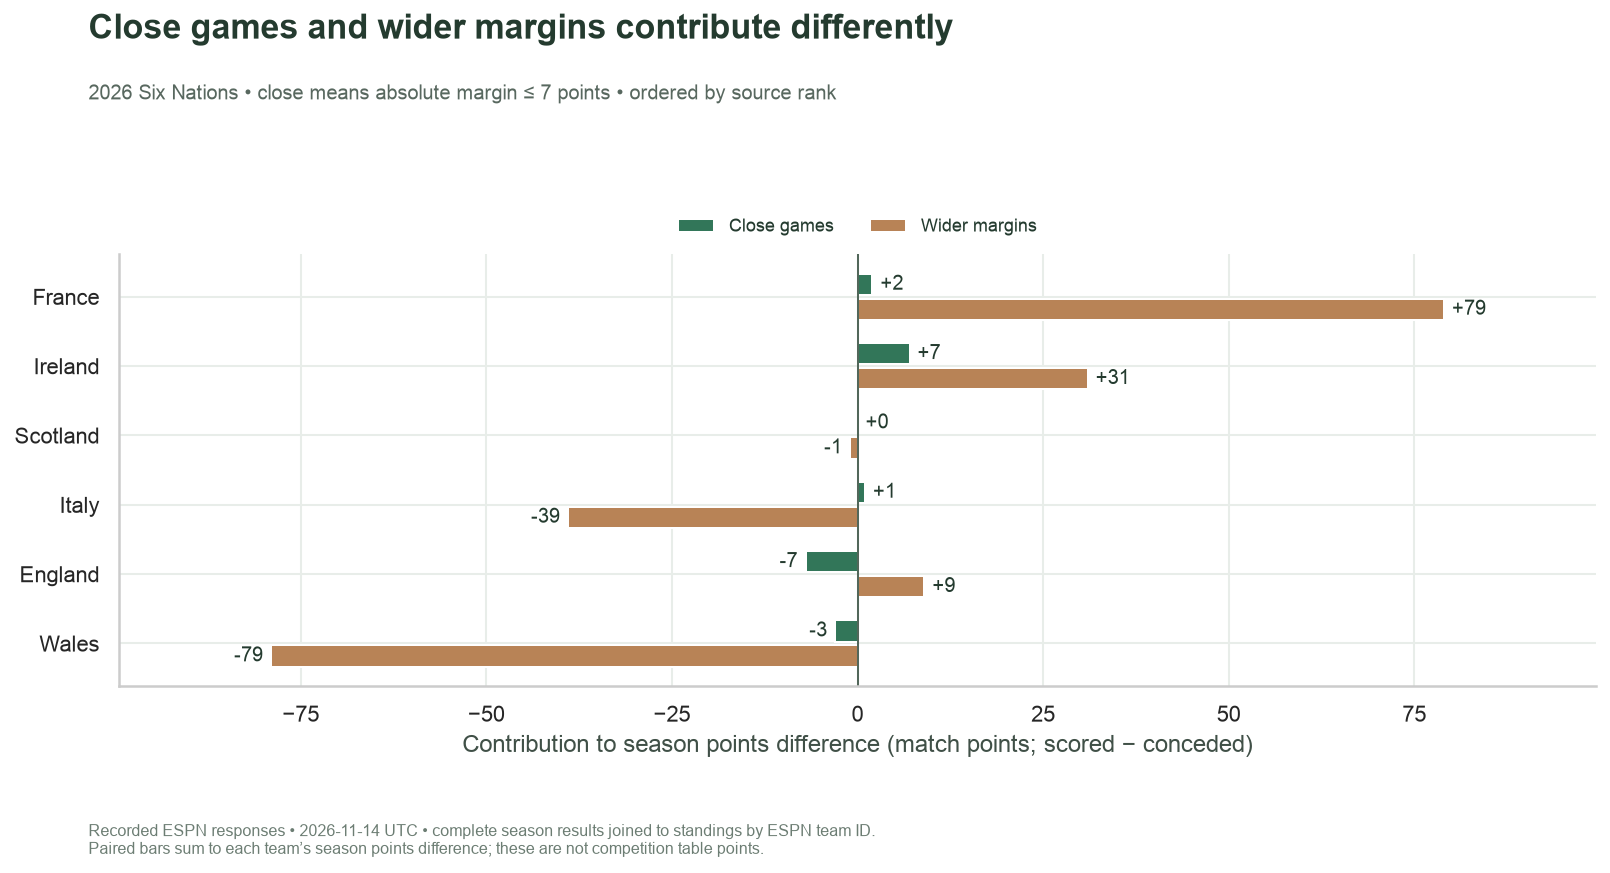

In [10]:
fig, ax = plt.subplots(figsize=(11.5, 6.1))
y = list(range(len(teams_frame)))
for offset, column, label, color in [
    (-0.18, "close_difference", "Close games", "#327659"),
    (0.18, "wider_difference", "Wider margins", "#B88356"),
]:
    bars = ax.barh([v + offset for v in y], teams_frame[column], height=0.31, label=label, color=color)
    ax.bar_label(bars, padding=4, fmt="%+d", fontsize=10)
ax.set_yticks(y, teams_frame.team_name)
ax.invert_yaxis()
ax.axvline(0, color="#52675A", lw=1)
lo = min(0, teams_frame[["close_difference", "wider_difference"]].min().min())
hi = max(0, teams_frame[["close_difference", "wider_difference"]].max().max())
pad = max(8, (hi - lo) * 0.13)
ax.set(
    xlabel="Contribution to season points difference (match points; scored − conceded)",
    xlim=(lo - pad, hi + pad),
)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.12), fontsize=9)
chart(
    fig,
    "Close games and wider margins contribute differently",
    f"2026 Six Nations • close means absolute margin ≤ {CLOSE_MARGIN} points • ordered by source rank",
    source_label + " • complete season results joined to standings by ESPN team ID.\n"
    "Paired bars sum to each team’s season points difference; these are not competition table points.",
)

## See which scorelines cross the threshold

The next plot preserves each final score. Its signed x-axis is **home score minus away score**, so left of zero is an away win. The shaded band is the chosen close-game interval. Changing the threshold changes the classification, not any score, win/loss result, source rank or season total. Kickoff labels use UTC dates.

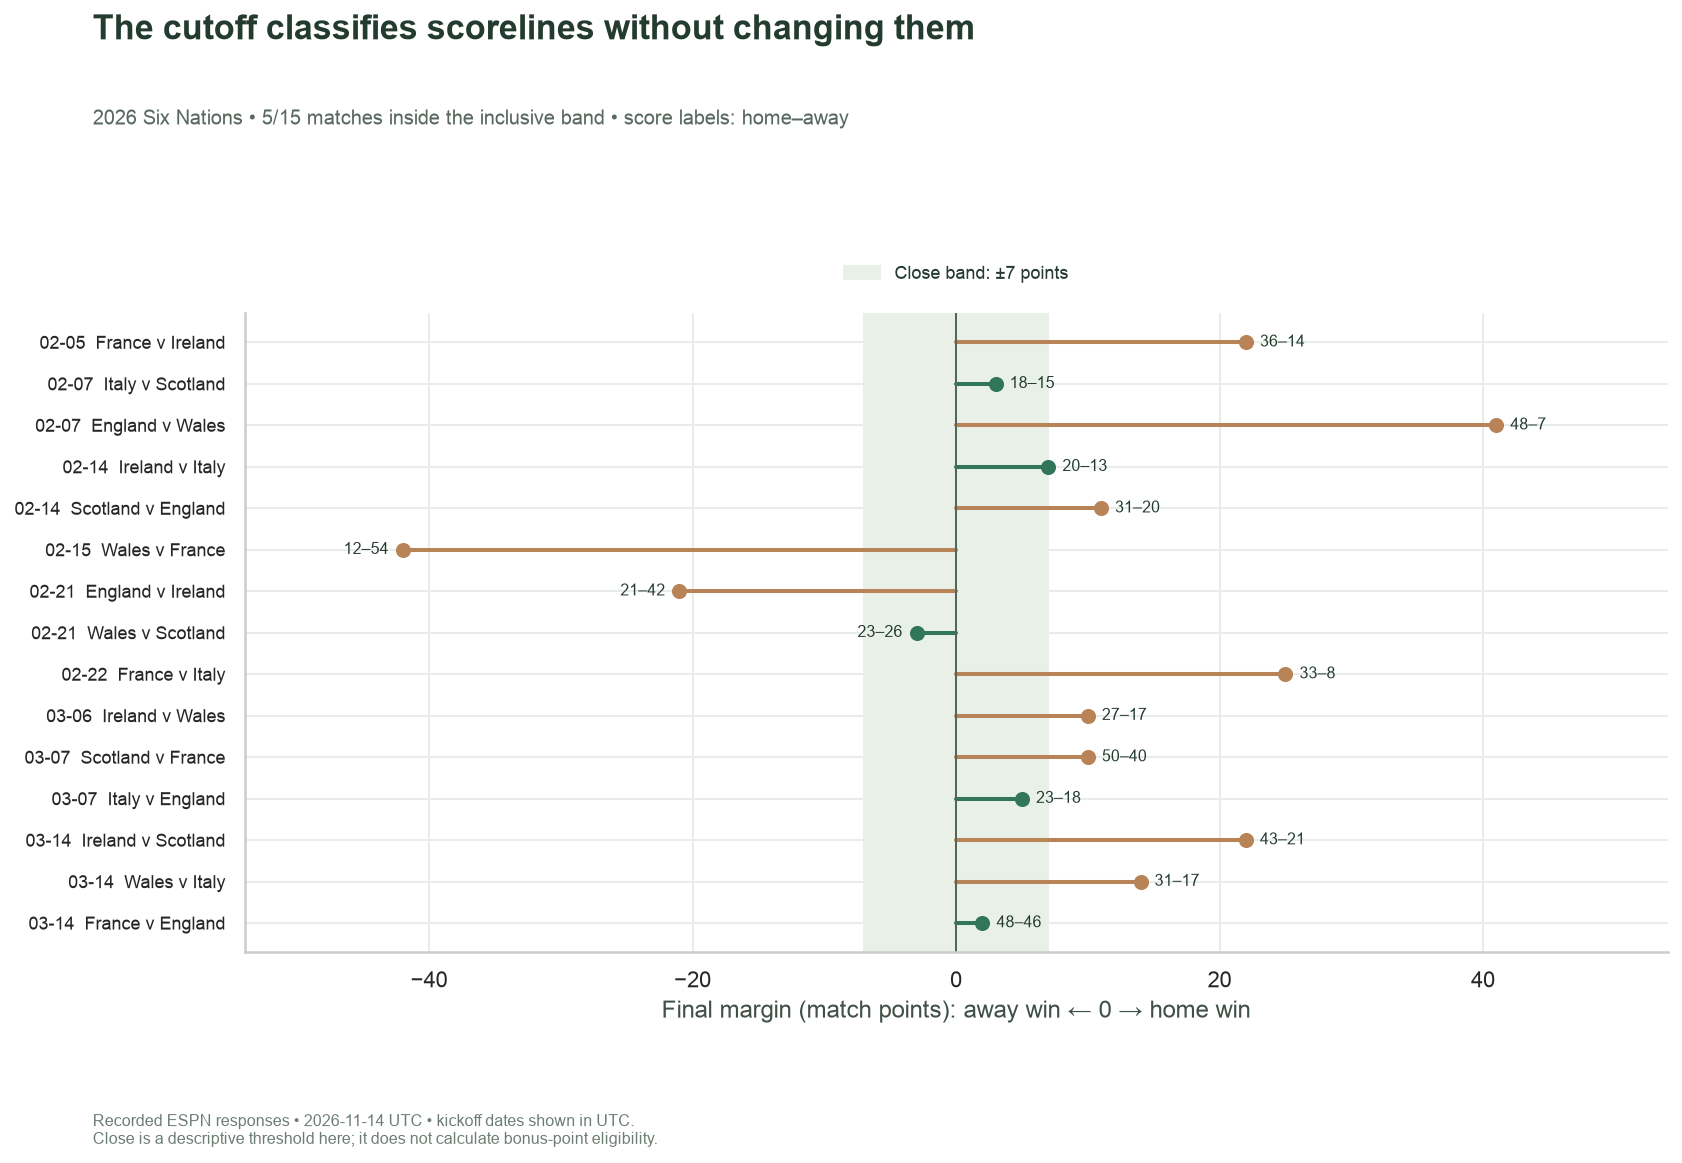

In [11]:
fig, ax = plt.subplots(figsize=(12, 8.2))
y = list(range(len(matches_frame)))
ax.axvspan(-CLOSE_MARGIN, CLOSE_MARGIN, color="#E9F0E8", label=f"Close band: ±{CLOSE_MARGIN} points")
for i, r in enumerate(matches_frame.itertuples()):
    color = "#327659" if r.is_close else "#B88356"
    ax.plot([0, r.home_margin], [i, i], color=color, lw=2)
    ax.scatter(r.home_margin, i, c=color, s=42, zorder=3)
    ax.annotate(
        f"{int(r.home_score)}–{int(r.away_score)}",
        (r.home_margin, i),
        xytext=(7 if r.home_margin >= 0 else -7, 0),
        textcoords="offset points",
        ha="left" if r.home_margin >= 0 else "right",
        va="center",
        fontsize=8,
    )
labels = [
    f"{r.kickoff_utc:%m-%d}  {r.home_team_name} v {r.away_team_name}" for r in matches_frame.itertuples()
]
ax.set_yticks(y, labels, fontsize=9)
ax.invert_yaxis()
ax.axvline(0, color="#52675A", lw=1)
bound = max(CLOSE_MARGIN, abs(matches_frame.home_margin).max()) + 12
ax.set(xlabel="Final margin (match points): away win ← 0 → home win", xlim=(-bound, bound))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.10), fontsize=9)
chart(
    fig,
    "The cutoff classifies scorelines without changing them",
    f"2026 Six Nations • {close_count}/{len(matches_frame)} matches inside the inclusive band "
    "• score labels: home–away",
    source_label + " • kickoff dates shown in UTC.\n"
    "Close is a descriptive threshold here; it does not calculate bonus-point eligibility.",
)

## Reconcile both directions and all totals

These checks require source completeness and agreement for the selected season, rather than assuming one fixed team ranking. They also verify the contribution split across reasonable thresholds. A failed comparison should be investigated as a source/schema discrepancy; the notebook does not fill missing team totals with zero or hide a mismatched score.

In [12]:
%%sql
CREATE TABLE checks AS
SELECT 'Completed source events are unique and populated' AS check_name,count(*)>0 AND count(*)=count(DISTINCT event_id) AND bool_and(completed) AS passed FROM results
UNION ALL SELECT 'Final scores are present and nonnegative',count(*)=count(home_score) AND count(*)=count(away_score) AND bool_and(home_score>=0 AND away_score>=0) FROM results
UNION ALL SELECT 'Standings team keys are unique',count(*)>0 AND count(*)=count(DISTINCT (league,season,team_id)) FROM standings
UNION ALL SELECT 'Two team perspectives per match',(SELECT count(*) FROM team_games)=2*(SELECT count(*) FROM results)
UNION ALL SELECT 'Every result team has standings',count(*)=0 FROM reconstructed r LEFT JOIN standings s USING(league,season,team_id) WHERE s.team_id IS NULL
UNION ALL SELECT 'Every standing has reconstructed results',count(*)=count(played) FROM comparison
UNION ALL SELECT 'Played/won/drawn/lost agree',bool_and(played=games_played AND won=wins AND drawn=draws AND lost=losses) FROM comparison
UNION ALL SELECT 'Scored/conceded/difference agree',bool_and(scored=points_for AND conceded=points_against AND difference=points_difference) FROM comparison
UNION ALL SELECT 'Difference equals scored minus conceded',bool_and(difference=scored-conceded) FROM comparison
UNION ALL SELECT 'Close and wider contributions reconcile',bool_and(difference=close_difference+wider_difference) FROM comparison
UNION ALL SELECT 'Team differences cancel across season',sum(difference)=0 FROM comparison
UNION ALL SELECT 'Each close match contributes two team rows',(SELECT sum(close_games) FROM comparison)=2*(SELECT count(*) FROM match_margins WHERE is_close);
SELECT check_name,CASE WHEN passed THEN 'PASS' ELSE error(check_name) END AS result FROM checks;

Running query in 'DuckDBPyConnection'

12 rows affected.

,check_name,result
0,Completed source events are unique and populated,PASS
1,Final scores are present and nonnegative,PASS
2,Standings team keys are unique,PASS
3,Two team perspectives per match,PASS
4,Every result team has standings,PASS
5,Every standing has reconstructed results,PASS
6,Played/won/drawn/lost agree,PASS
7,Scored/conceded/difference agree,PASS
8,Difference equals scored minus conceded,PASS
9,Close and wider contributions reconcile,PASS


In [13]:
prose(audit(server))

Replay audit: exactly one scoreboard and one standings request; both matched the recorded parameters.

## Focused experiment: widen “close” from 7 to 14 points

Change only **CLOSE_MARGIN from 7 to 14** while keeping the data mode fixed. Predict which additional fixtures enter the shaded band. Compare the close-game count and the paired contribution bars; individual scorelines and each team’s combined points difference should stay identical. The README provides a separate-output command.

A wider definition does not imply different match outcomes, team strength or competition points. It only reallocates existing margins between two descriptive groups. Restore **CLOSE_MARGIN = 7**. If testing live mode separately, compare its source availability first: later source corrections are a second variable, and failures are never replaced by recordings.

In [14]:
connection.close()
cleanup(server, thread, previous)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)